# How much should you trust a model's score?

Every model ships with a number: 92% accuracy, AUC 0.85, R² 0.3. This notebook shows how far that number can be
from the model's real performance, and which habits make it worse.

**The trick:** all the data here comes from simulations where the truth is known. So besides the usual evaluation,
every model is also scored on 100,000 fresh examples it has never seen. That fresh-data score is the truth the
evaluation is trying to estimate, and the gap between the two is what each lesson measures.

| Lesson | Question |
|---|---|
| 1 | Which classification metric, and which threshold? |
| 2 | Which regression metric, and can I trust an interval? |
| 3 | How noisy is a cross-validation score? |
| 4 | How does information leak from test into training? |
| 5 | Does tuning make the score optimistic? |
| 6 | Is model B really better than model A? |
| 7 | Will more data help? |
| 8 | Putting it together: a model-quality report |

In [1]:
import json
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from evallab import config, leakage, regression, truth

R = config.RESULTS
load = lambda name: json.loads((R / name).read_text())
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

## Lesson 1: choosing the classification metric

### 1a. Rare positives

The same kind of problem with 50%, 10% and 1% positives. "Always 'no'" is a model that never predicts the rare
class.

In [2]:
l1 = load("l1_classification.json")
pd.DataFrame(l1["1a_imbalance"]).T[["accuracy", "balanced accuracy", "ROC AUC", "PR AUC", "Brier skill"]]

,accuracy,balanced accuracy,ROC AUC,PR AUC,Brier skill
50% positives: model,0.759,0.759,0.843,0.843,0.353
50% positives: always 'no',0.498,0.500,0.500,0.502,-1.004
50% positives: true probabilities,0.762,0.762,0.844,0.844,0.356
10% positives: model,0.910,0.611,0.863,0.476,0.244
10% positives: always 'no',0.899,0.500,0.500,0.101,-0.110
10% positives: true probabilities,0.910,0.612,0.866,0.483,0.250
1% positives: model,0.990,0.509,0.868,0.139,0.072
1% positives: always 'no',0.990,0.500,0.500,0.010,-0.008
1% positives: true probabilities,0.990,0.511,0.885,0.170,0.091


At 1% positives the model's accuracy equals the do-nothing model's (99%). ROC AUC hardly moves as positives
get rarer, because it only asks whether positives rank above negatives. PR AUC falls toward the prevalence, because
it asks how many of the flagged cases are real, and that is what gets hard when positives are rare. For rare
events, report PR AUC (or precision at a useful recall) next to ROC AUC, and never accuracy alone.

### 1b. Are the probabilities honest?

In [3]:
pd.DataFrame(l1["1b_calibration"]).T[["ROC AUC", "log loss", "Brier", "calibration error", "mean prediction",
                                       "prevalence"]]

,ROC AUC,log loss,Brier,calibration error,mean prediction,prevalence
logistic,0.862,0.236,0.069,0.003,0.100,0.101
"logistic, balanced weights",0.861,0.468,0.154,0.243,0.344,0.101
gradient boosting,0.822,0.333,0.081,0.050,0.051,0.101
"balanced, recalibrated",0.857,0.243,0.069,0.003,0.101,0.101
true probabilities,0.866,0.233,0.068,0.002,0.100,0.101


`class_weight="balanced"` is a common fix for imbalance. It leaves ROC AUC unchanged (0.861 vs 0.862), so a
ranking metric can't see anything wrong, but every probability is inflated: on average it predicts 34% when the
real rate is 10%. Log loss and Brier score (proper scoring rules: they reward honest probabilities) and the
calibration error catch it. Recalibrating on a held-out split fixes it.

### 1c. Choosing the threshold from costs

Missing a positive costs 5; a false alarm costs 1. With honest probabilities, flag a case when its probability is
above 1/(1+5) = 0.167.

In [4]:
pd.DataFrame(l1["1c_thresholds"]).T

,threshold,expected cost per case,share flagged
0.5 (default),0.500,0.398,0.038
F1-maximising (chosen on held-out split),0.246,0.307,0.122
cost-based 1/(1+5) = 0.167,0.167,0.292,0.184
cost-based 0.167 on the balanced model,0.167,0.560,0.640
cost-based 0.167 on true probabilities,0.167,0.286,0.185


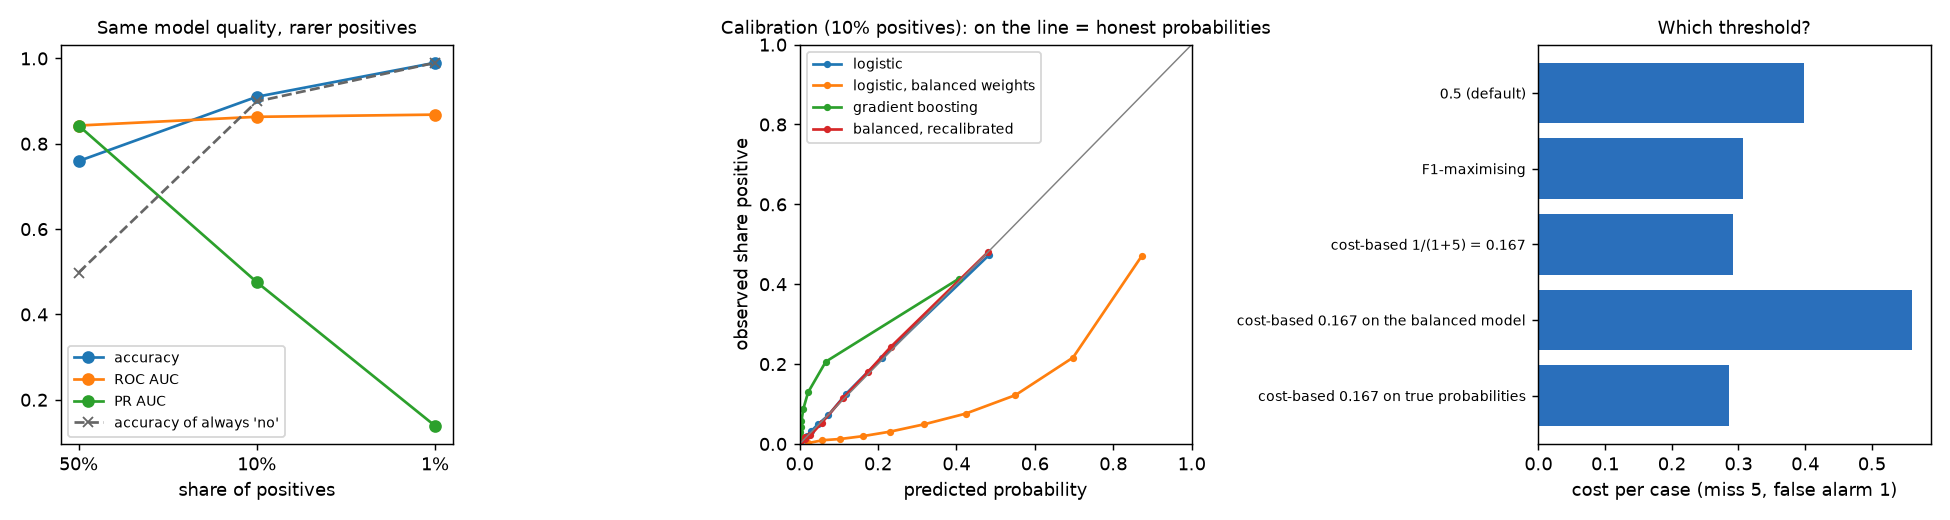

In [5]:
display(Image(str(config.FIGURES / "l1_classification.png")))

The cost-based threshold gets within 0.006 of the best possible cost. The default 0.5 costs 37% more. And
the same cost threshold applied to the *balanced* model is the worst option of all, because its probabilities are
not probabilities. Thresholds and calibration go together.

### 1d. Real data: German credit

1,000 loans, 30% bad. Approving a bad loan costs 5; rejecting a good one costs 1.

In [6]:
print(l1["1d_info"])
pd.DataFrame(l1["1d_german"]).T

{'n': 1000, 'bad_rate': 0.3}


,ROC AUC,Brier,calibration error,accuracy at 0.5,cost per loan at 0.5,cost per loan at 0.167,"cost per loan, approve everyone","cost per loan, reject everyone"
logistic,0.785,0.166,0.028,0.748,0.896,0.538,1.5,0.7
gradient boosting,0.774,0.177,0.101,0.758,0.858,0.642,1.5,0.7


At the default 0.5 threshold, both models cost more per loan than simply rejecting everyone (0.70). At the
cost threshold the logistic model costs 0.54. The model didn't change; the decision rule did.

## Lesson 2: evaluating regression

### 2a. The metric decides the winner

A skewed target (like prices). Five models, each built for one metric, scored on 100,000 fresh rows. Rows starting
with `oracle` use the true distribution: the best possible prediction for each metric.

In [7]:
l2 = load("l2_regression.json")
pd.DataFrame(l2["2a_metric_choice"]).T[["RMSE", "MAE", "MAPE", "pinball 0.9", "mean bias"]]

,RMSE,MAE,MAPE,pinball 0.9,mean bias
squared error (mean),23.541,12.778,0.574,6.277,0.280
absolute error (median),23.312,11.881,0.473,7.344,-3.509
MAPE-weighted (low median),27.640,13.263,0.398,10.777,-10.365
quantile 0.9,30.994,20.684,1.161,3.945,15.993
"log target, exp back",23.360,12.029,0.471,7.337,-3.308
oracle: mean,21.949,11.909,0.533,5.937,0.044
oracle: median,22.569,11.475,0.443,7.223,-3.714
oracle: mape,25.810,12.669,0.381,10.185,-9.627
oracle: quantile,35.329,23.411,1.268,3.592,20.283


MAE rewards the median, MAPE rewards a value *below* the median (it pays you to forecast low), pinball loss
rewards the chosen quantile. Only the mean model is unbiased, which matters when forecasts are summed.

### 2b. R² depends on the data, not just the model (live)

In [8]:
pd.DataFrame(regression.r2_range(n=50_000))

,"narrow x, U(-1, 1)","wide x, U(-3, 3)"
RMSE,1.004,0.998
R2,0.569,0.923


Same model, same noise, same error. R² differs only because the inputs are more spread out in one sample.

### 2c. Does an 80% interval contain 80%?

In [9]:
pd.DataFrame(l2["2c_intervals"]).T

,coverage,"coverage, quiet third","coverage, middle third","coverage, noisy third",mean width
naive: prediction +/- 1.28 RMSE,0.832,0.994,0.858,0.645,4.260
"quantile regression (10%, 90%)",0.740,0.729,0.749,0.743,3.389
split conformal (constant width),0.794,0.987,0.809,0.587,3.756
conformalized quantile (CQR),0.803,0.840,0.796,0.774,3.737
oracle (true 10%-90%),0.800,0.799,0.804,0.798,3.597


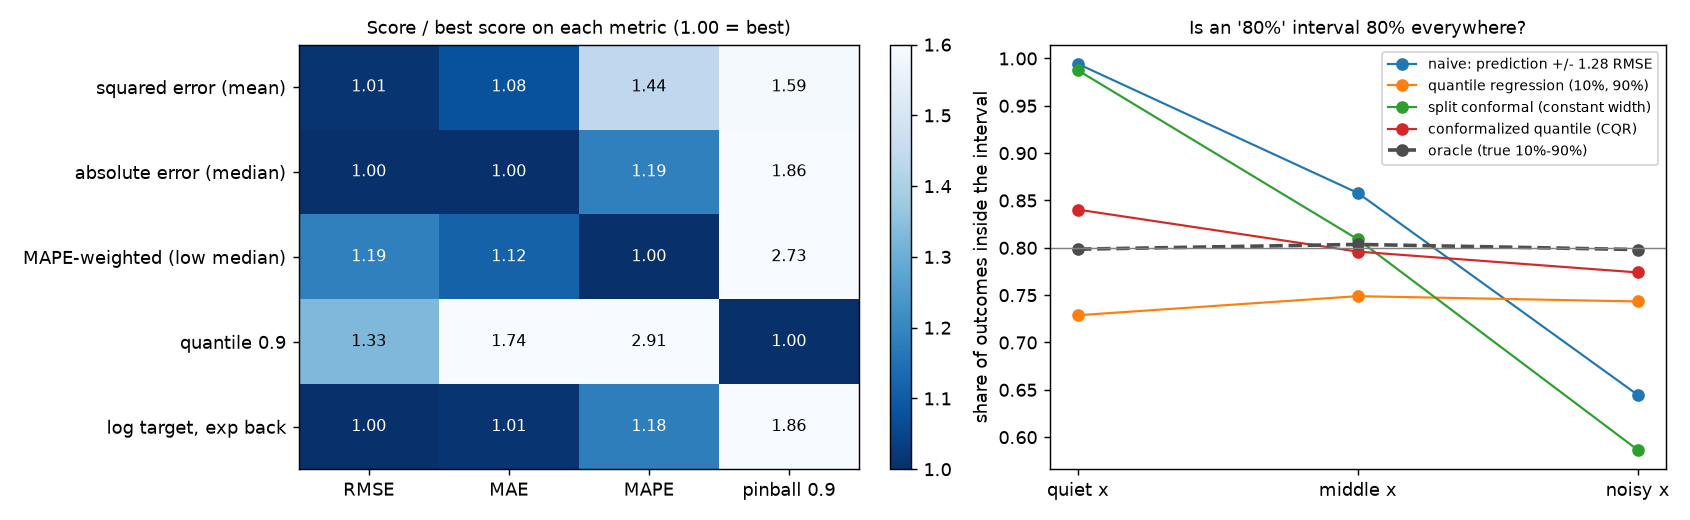

In [10]:
display(Image(str(config.FIGURES / "l2_regression.png")))

Overall coverage can be right while the interval is far too wide where things are calm and too narrow
where risk is highest. Conformalized quantile regression (CQR) gets closest to the true interval.

### 2d. Real data: California housing

In [11]:
display(pd.DataFrame(l2["2d_california"]).T[["RMSE", "MAE", "MAPE", "pinball 0.9", "R2"]])
cap = l2["2d_cap"]
print(f"{cap['capped_rows']} of {cap['n']} homes are recorded at the $500k cap (true price unknown, higher)")

,RMSE,MAE,MAPE,pinball 0.9,R2
squared error (mean),0.458,0.303,0.171,0.152,0.843
absolute error (median),0.483,0.304,0.161,0.174,0.825
MAPE-weighted (low median),0.535,0.328,0.158,0.226,0.785
quantile 0.9,0.737,0.556,0.366,0.090,0.592
"log target, exp back",0.469,0.301,0.158,0.169,0.835


992 of 20640 homes are recorded at the $500k cap (true price unknown, higher)


## Lesson 3: a cross-validation score is a noisy estimate

A logistic regression on 200 examples, 200 independent training sets. For each, the true error of the fitted
model is compared with each estimate of it.

In [12]:
l3 = load("l3_estimators.json")
print(f"best possible error {l3['bayes_error']:.3f}; fitted models' true error {l3['mean_truth']:.3f} "
      f"(varies by {l3['sd_truth']:.3f} between training sets)")
pd.DataFrame(l3["methods"]).T[["bias", "sd_of_gap", "corr_with_truth"]]

best possible error 0.239; fitted models' true error 0.270 (varies by 0.009 between training sets)


,bias,sd_of_gap,corr_with_truth
training error,-0.066,0.033,0.153
holdout 70/30,0.010,0.061,0.075
5-fold CV,0.007,0.036,0.172
10-fold CV,0.003,0.036,0.184
5x5-fold CV,0.009,0.034,0.134
.632 bootstrap,-0.008,0.032,0.148


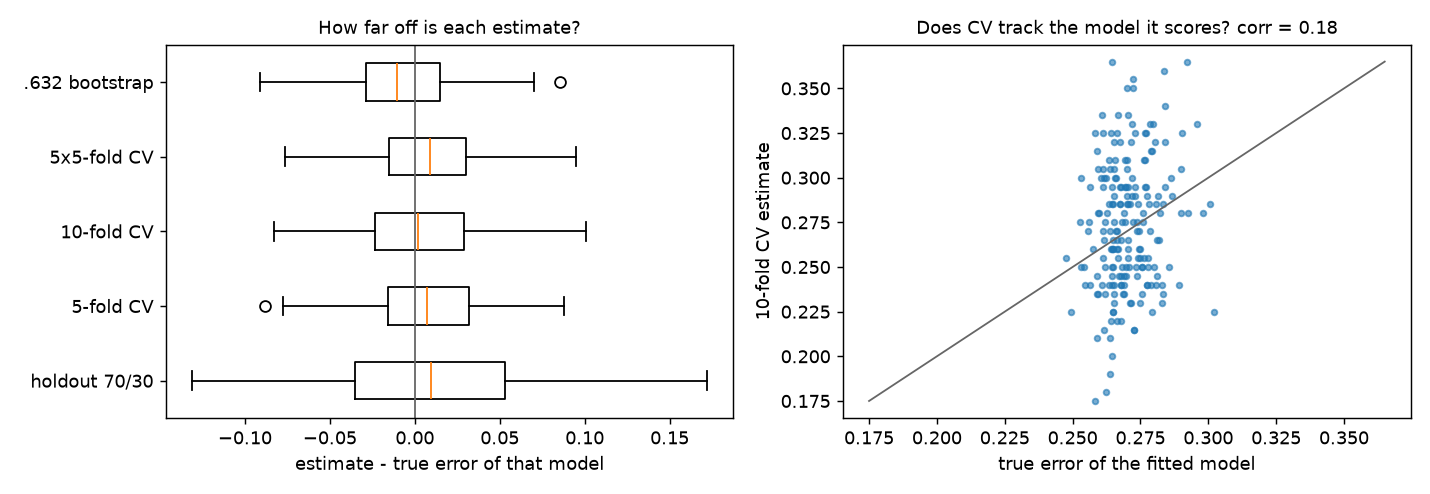

In [13]:
display(Image(str(config.FIGURES / "l3_estimators.png")))

K-fold CV is right on average but typically 3.6 points off for any one training set, and it hardly moves with
the error of the particular model you trained (right panel; Hastie et al., *Elements of Statistical Learning*,
7.12). A single holdout is twice as noisy. Training error flatters by 6.6 points.

## Lesson 4: leakage

### 4a. The wrong way to cross-validate (live)

Fifty examples, 5,000 random features, labels that are coin flips: the true error is 50%. Choose the 100 features
most related to the label using *all* the labels, then cross-validate:

In [14]:
pd.DataFrame([leakage.wrong_vs_right(seed) for seed in range(10)]).describe().loc[["mean", "min", "max"]]

,"wrong way (select, then CV)",right way (select inside each fold)
mean,0.008,0.48
min,0.000,0.42
max,0.040,0.56


### 4b and 4c. Same patient in both folds; overlapping time targets

In [15]:
l4 = load("l4_leakage.json")
pd.concat({k: pd.DataFrame(v["results"]).T[["mean", "p10", "p90"]] for k, v in l4.items()})

mean    p10    p90
4a_wrong_way wrong way (select, then CV)          0.013  0.000  0.040
             right way (select inside each fold)  0.487  0.420  0.562
4b_grouped   random K-fold                        0.729  0.694  0.763
             group K-fold                         0.663  0.608  0.711
             truth (new patients)                 0.680  0.662  0.694
4c_time      shuffled K-fold                      0.020 -0.030  0.064
             contiguous K-fold                   -0.220 -0.280 -0.136
             purged + embargo K-fold             -0.224 -0.309 -0.139
             walk-forward                        -0.300 -0.426 -0.195
             truth (fresh series)                -0.203 -0.261 -0.153

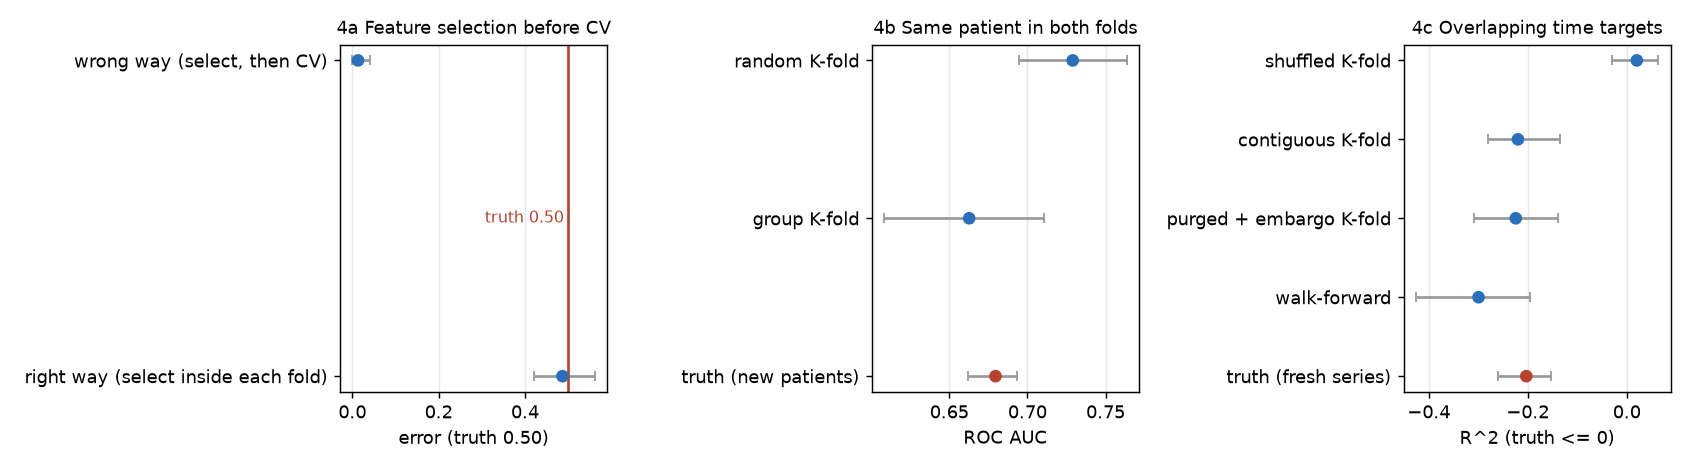

In [16]:
display(Image(str(config.FIGURES / "l4_leakage.png")))

On a time series with nothing to predict, shuffled CV reports an edge; the model actually loses. When does
purging (dropping training rows whose targets overlap the test period) matter? More folds and longer horizons:

In [17]:
pd.DataFrame(load("l4c_purge_sweep.json"))

,folds,horizon,contiguous K-fold,purged + embargo K-fold,truth,leak (contiguous - purged)
0,5,5,-0.161,-0.162,-0.151,0.001
1,5,20,-0.209,-0.212,-0.203,0.003
2,5,60,-0.284,-0.293,-0.229,0.009
3,20,5,-0.150,-0.152,-0.151,0.002
4,20,20,-0.184,-0.196,-0.203,0.012
5,20,60,-0.247,-0.274,-0.229,0.027
6,50,5,-0.145,-0.152,-0.151,0.007
7,50,20,-0.171,-0.196,-0.203,0.025
8,50,60,-0.195,-0.269,-0.229,0.074


## Lesson 5: tuning makes the winning score optimistic

Try m configurations, keep the one with the best cross-validation score, and report that score: it's the winner of
m noisy estimates. Nested CV puts the whole tuning procedure inside an outer loop.

In [18]:
l5 = load("l5_tuning.json")
pd.DataFrame(l5["5a_nested"])

,problem,m,claimed (best CV score),nested CV,truth,optimism of claimed,optimism of nested
0,pure noise,1,0.488,0.479,0.499,-0.012,-0.021
1,pure noise,10,0.424,0.484,0.499,-0.075,-0.015
2,pure noise,100,0.399,0.483,0.499,-0.100,-0.017
3,signal,1,0.443,0.434,0.445,-0.002,-0.011
4,signal,10,0.384,0.432,0.424,-0.040,0.007
5,signal,100,0.349,0.432,0.430,-0.081,0.002


### Choosing on a single validation group

Groups (machines, sites) each bend the shared pattern. Choose a configuration using one held-out group, or
leave-one-group-out CV over all twelve; then score the choice on 300 new groups.

In [19]:
pd.concat({k: pd.DataFrame(v) for k, v in l5["5b_one_group"].items()})

claimed  truth  regret
one validation group   mean    0.275  0.402   0.036
                       std     0.067  0.027   0.027
leave-one-group-out CV mean    0.354  0.380   0.014
                       std     0.031  0.017   0.013

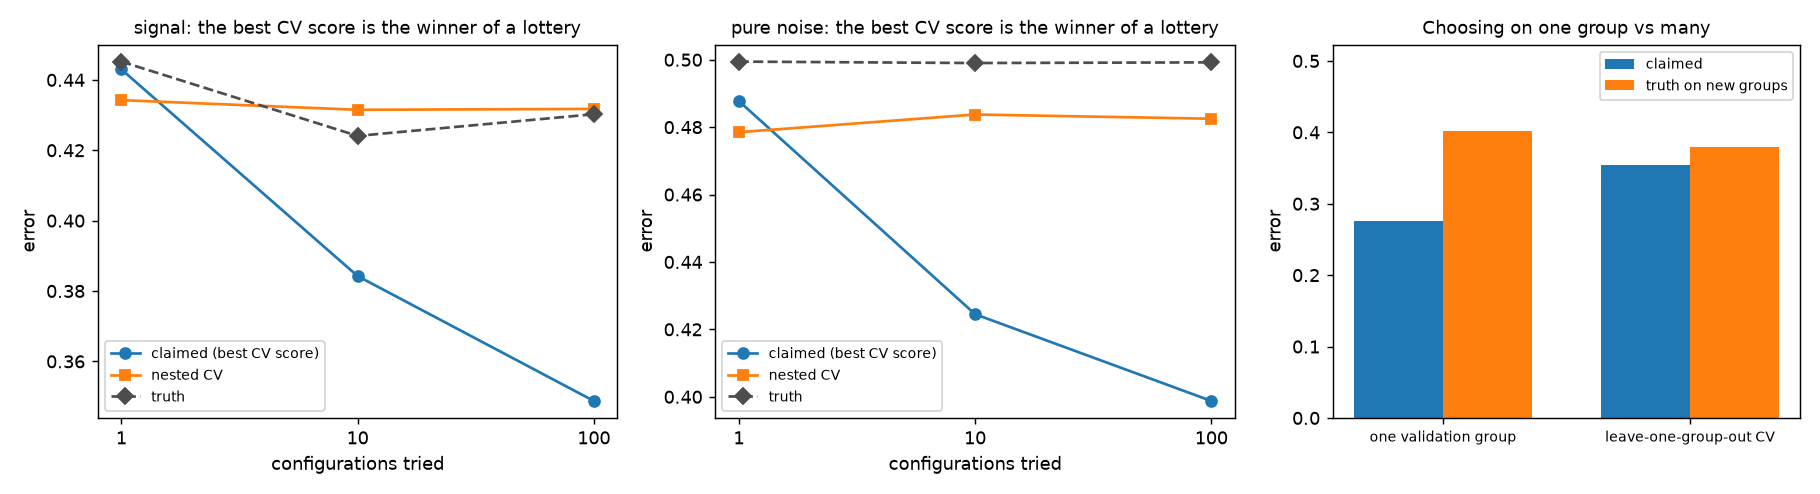

In [20]:
display(Image(str(config.FIGURES / "l5_tuning.png")))

## Lesson 6: is model B really better?

Two models that are exactly equally good (by construction). Each test is run on 500 independent datasets; at the 5%
level, at most 5% should call a winner. Then B is made truly better and the same tests' power is measured.

In [21]:
l6 = load("l6_compare.json")
display(pd.DataFrame(l6["rates"]))
l6["true errors when B is better"]

,equal models (false-positive rate),B truly better (power)
paired t-test on 10-fold CV,0.078,0.292
resampled t-test (15 splits),0.454,0.730
corrected resampled t-test,0.052,0.234
5x2cv paired t-test,0.052,0.172
McNemar on one holdout,0.052,0.118


{'model A error': 0.3928565,
 'model B error': 0.3341541666666667,
 'gap': 0.058702333333333336}

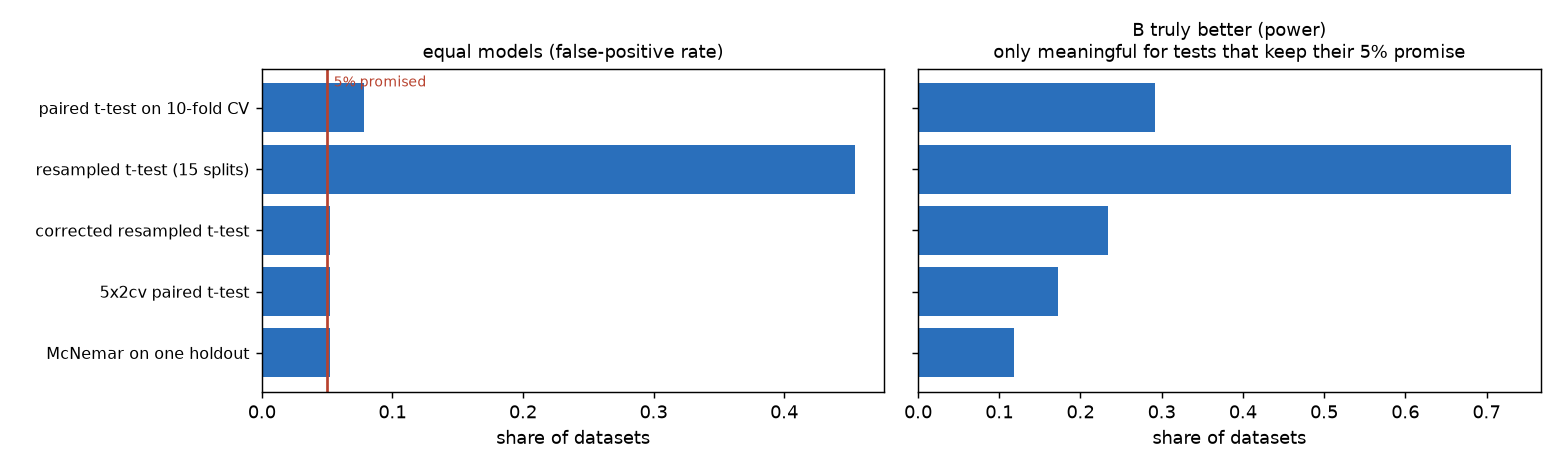

In [22]:
display(Image(str(config.FIGURES / "l6_compare.png")))

The resampled t-test on repeated random splits calls equal models different almost half the time: the
splits share most of their training data, so their results aren't independent and the test's variance is far too
small (Dietterich 1998). The correction of Nadeau and Bengio (2003), the 5x2cv test and McNemar's test keep their
promise. Power is low for all honest tests at 300 rows, even with a 6-point true difference: small datasets can't
separate close models.

## Lesson 7: will more data help?

A curved class boundary; three models. Training, cross-validation and true error by training size; the red line is
the best possible error.

In [23]:
l7 = load("l7_curves.json")
lc = pd.DataFrame(l7["learning"])
display(lc.pivot(index="n", columns="model", values="truth"))
print("tree depth chosen by CV:", l7["depth chosen by CV"], "| best depth on fresh data:", l7["depth best on truth"])

model,1-nearest neighbour (high variance),15-nearest neighbours,logistic regression (high bias)
n,,,
50,0.358,0.453,0.490
100,0.321,0.361,0.497
200,0.299,0.320,0.485
400,0.279,0.260,0.505
800,0.261,0.216,0.506
1600,0.244,0.188,0.512
3200,0.232,0.174,0.515


tree depth chosen by CV: 4 | best depth on fresh data: 4


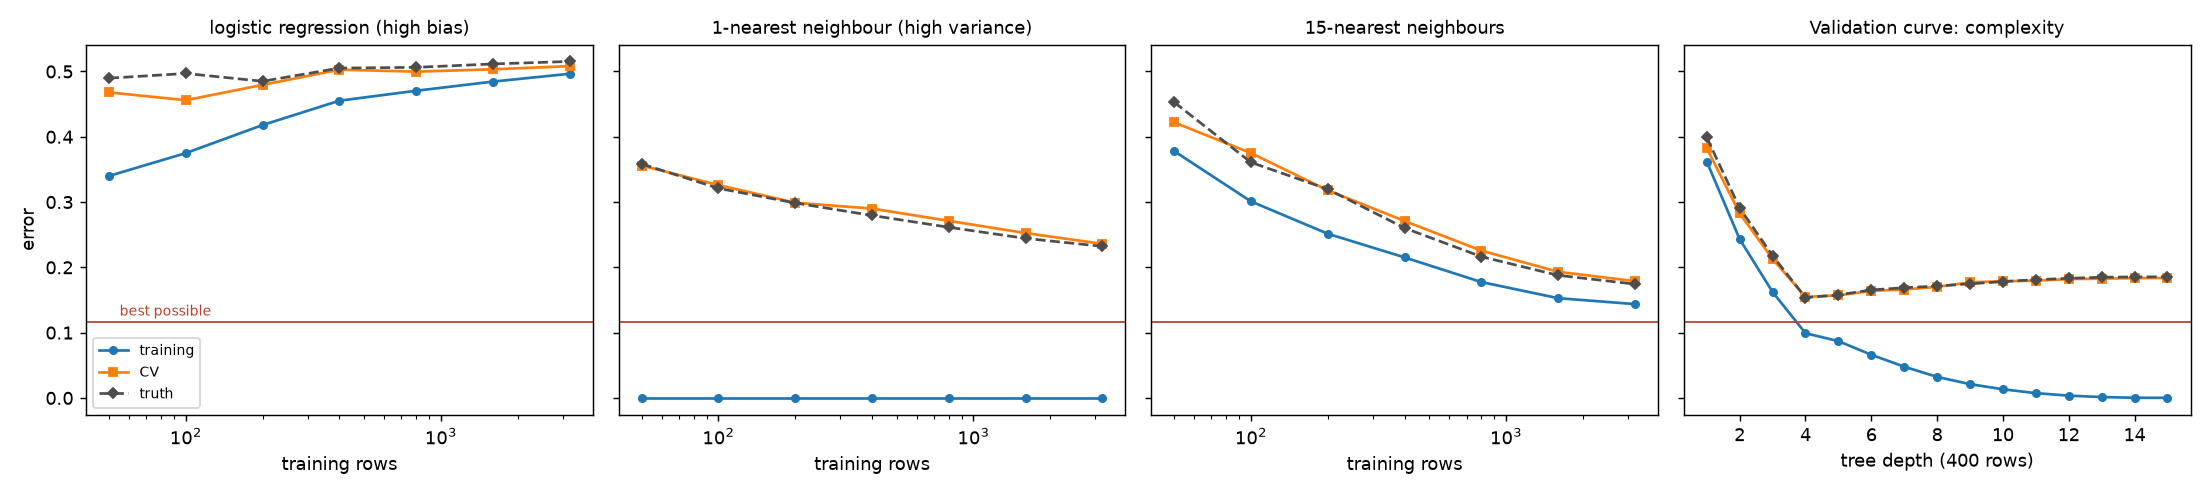

In [24]:
display(Image(str(config.FIGURES / "l7_curves.png")))

- **High bias** (logistic regression): training and CV error meet, far above the floor. More data won't help;
  a more flexible model will.
- **High variance** (1-nearest neighbour): training error 0, a large gap to CV. More data helps, slowly.
- **Validation curve**: CV error tracks the truth closely across tree depths and picks the right depth (4); the
  training error keeps falling and would pick the deepest tree.

## Lesson 8: a model-quality report

`report.model_report` combines the lessons: an untouched holdout set aside first (lesson 5), a leaderboard with a
no-skill baseline, proper scores, calibration and cost with bootstrap intervals (lessons 1 and 3), group-aware folds
when there are groups (lesson 4), and a holdout check with confusion matrix, curves, permutation importance and a
learning curve (lesson 7). Here on German credit:

In [25]:
display(Markdown((config.REPORTS / "german_credit_report.md").read_text().replace("figures/", "../reports/figures/")))

# Model-quality report: german_credit

1000 rows, 30% positive. Cost of a miss 5, of a false alarm 1, so the decision threshold is 0.167.

## Leaderboard (5-fold CV on the development split; 90% bootstrap intervals)

| Model | log loss | Brier | ROC AUC | PR AUC | calibration error | expected cost |
|---|---|---|---|---|---|---|
| no skill (predict the base rate) | 0.611 (0.587-0.633) | 0.210 (0.198-0.221) | 0.500 (0.500-0.500) | 0.300 (0.271-0.326) | 0.048 (0.025-0.060) | 0.700 (0.674-0.729) |
| logistic | 0.521 (0.485-0.555) | 0.174 (0.161-0.187) | 0.770 (0.740-0.796) | 0.587 (0.528-0.636) | 0.054 (0.043-0.083) | 0.537 (0.481-0.600) |
| random forest | 0.500 (0.477-0.523) | 0.165 (0.156-0.175) | 0.797 (0.769-0.824) | 0.628 (0.578-0.686) | 0.063 (0.054-0.096) | 0.515 (0.476-0.555) |
| gradient boosting | 0.589 (0.529-0.652) | 0.178 (0.163-0.196) | 0.779 (0.747-0.810) | 0.574 (0.520-0.633) | 0.098 (0.079-0.123) | 0.583 (0.510-0.655) |

## Winner on the untouched holdout (200 rows): random forest

| Metric | Value |
|---|---|
| log loss | 0.494 |
| Brier | 0.162 |
| ROC AUC | 0.801 |
| PR AUC | 0.649 |
| calibration error | 0.079 |
| expected cost | 0.550 |
| cost, approve/accept everyone | 1.500 |
| cost, reject/flag everyone | 0.700 |

At the cost threshold: 57 positives caught, 3 missed, 95 false alarms, 45 correct negatives.

## Permutation importance on the holdout (top 10)

- checking_status: +0.0753
- credit_amount: +0.0139
- duration: +0.0120
- credit_history: +0.0117
- purpose: +0.0094
- age: +0.0089
- savings_status: +0.0051
- other_payment_plans: +0.0045
- property_magnitude: +0.0042
- installment_commitment: +0.0039

![report](../reports/figures/l8_german_credit_report.png)


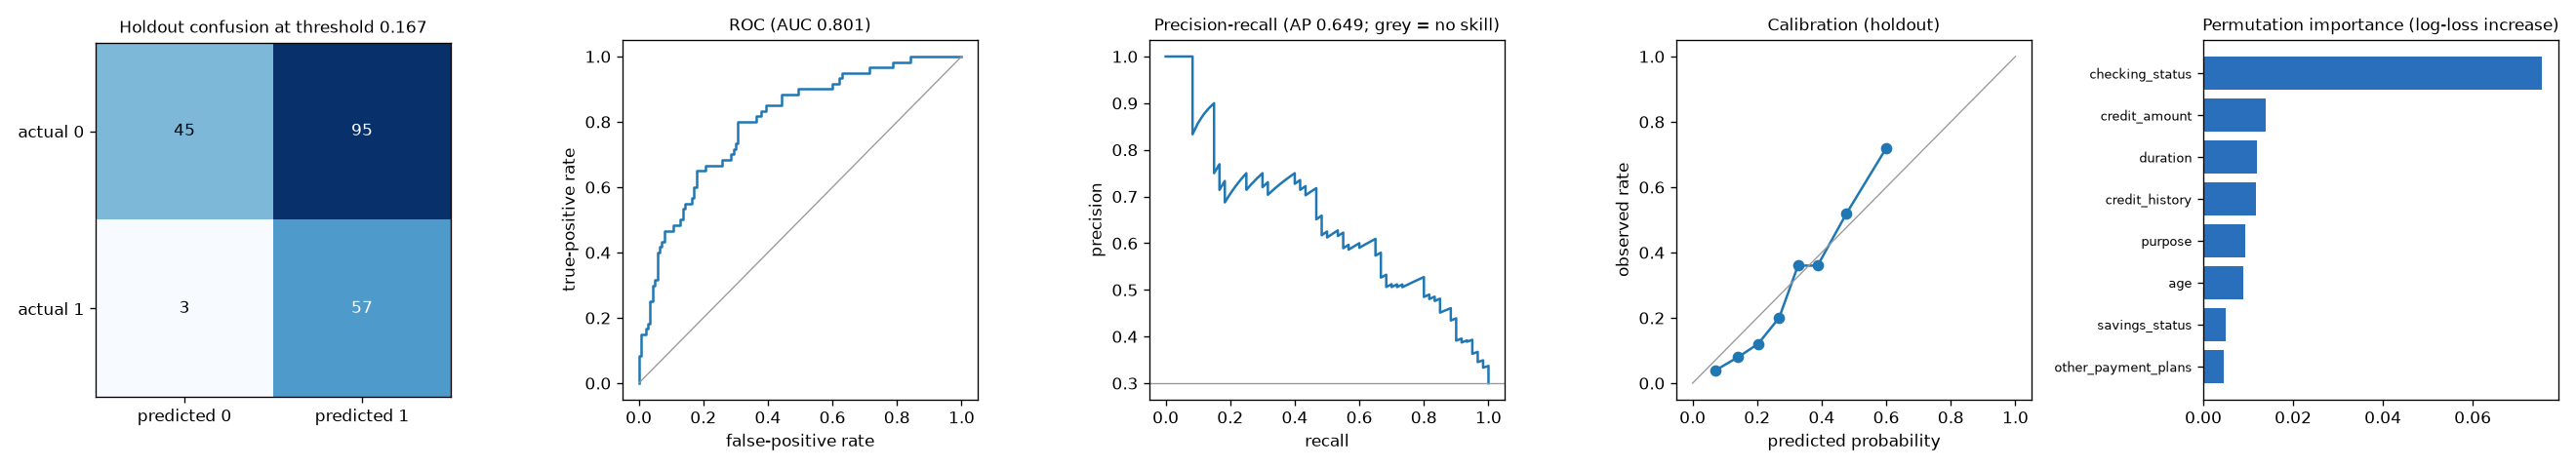

In [26]:
display(Image(str(config.FIGURES / "l8_german_credit_report.png")))